In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Définition de l'architecture du CNN
def build_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

model = build_model()
model.summary()

# 2. Compilation du modèle
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# 3. Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(filepath='best_fine_tuned_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
]

# 4. Entraînement
HISTORY_EPOCHS = 5
history = model.fit(
    train_generator,
    epochs=HISTORY_EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,921 (42.61 MB)

 Trainable params: 11,169,217 (42.61 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6777 - auc: 0.7384 - loss: 0.7230
Epoch 1: val_loss improved from None to 0.27335, saving model to best_fine_tuned_model.keras

Epoch 1: finished saving model to best_fine_tuned_model.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 6010s 9s/step - accuracy: 0.7249 - auc: 0.7970 - loss: 0.6193 - val_accuracy: 0.8860 - val_auc: 0.9265 - val_loss: 0.2733
Epoch 2/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7887 - auc: 0.8716 - loss: 0.4750
Epoch 2: val_loss improved from 0.27335 to 0.24178, saving model to best_fine_tuned_model.keras

Epoch 2: finished saving model to best_fine_tuned_model.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 4491s 6s/step - accuracy: 0.7987 - auc: 0.8806 - loss: 0.4565 - val_accuracy: 0.8999 - val_auc: 0.9586 - val_loss: 0.2418
Epoch 3/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8223 - auc: 0.9015 - loss: 0.4131
Epoch 3: val_loss did not improve from 0.24178
702/702 ━━━━━━━━━━━━━━━━━━━━ 4608s 7s/step

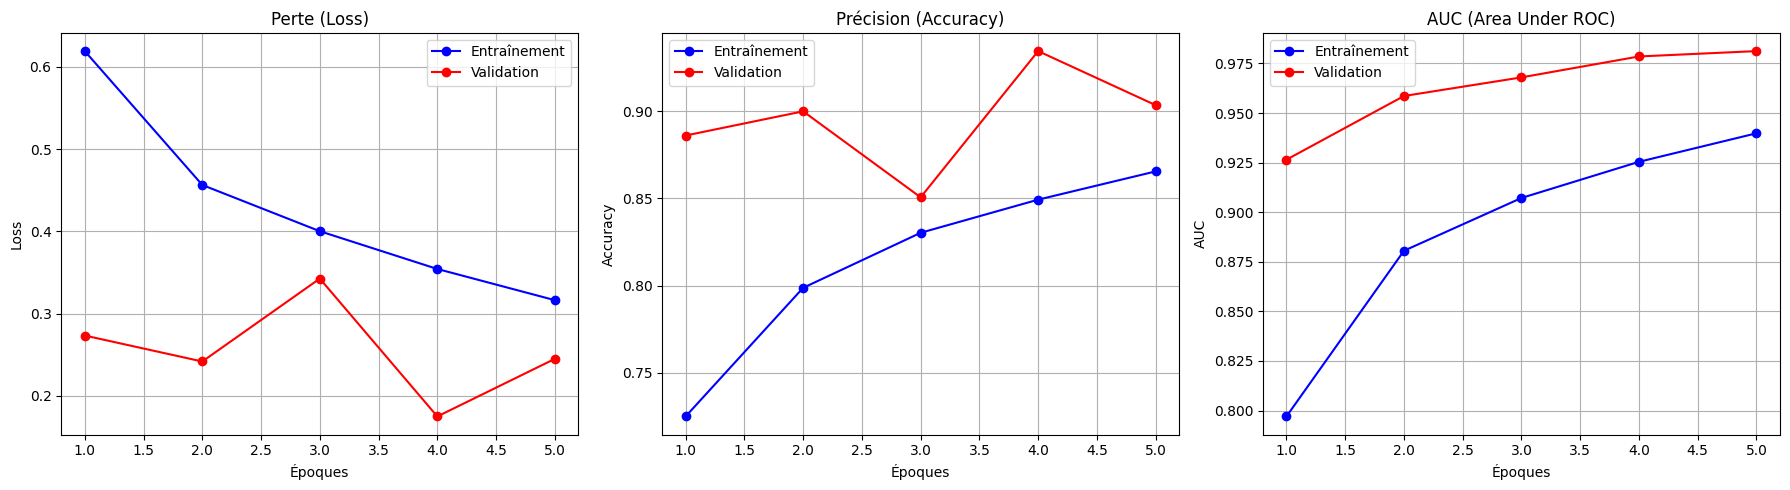

In [12]:
import matplotlib.pyplot as plt

# Récupération des données de l'historique d'entraînement
acc = history.history.get('accuracy', [])
val_acc = history.history.get('val_accuracy', [])
loss = history.history.get('loss', [])
val_loss = history.history.get('val_loss', [])
auc = history.history.get('auc', [])
val_auc = history.history.get('val_auc', [])

epoches_range = range(1, len(acc) + 1)

# Configuration de la figure avec 2 ou 3 sous-graphiques selon la présence de l'AUC
num_subplots = 3 if auc else 2
fig, axs = plt.subplots(1, num_subplots, figsize=(6 * num_subplots, 5))

# 1. Courbe de Loss
axs[0].plot(epoches_range, loss, 'bo-', label='Entraînement')
axs[0].plot(epoches_range, val_loss, 'ro-', label='Validation')
axs[0].set_title('Perte (Loss)')
axs[0].set_xlabel('Époques')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True)

# 2. Courbe d'Accuracy
axs[1].plot(epoches_range, acc, 'bo-', label='Entraînement')
axs[1].plot(epoches_range, val_acc, 'ro-', label='Validation')
axs[1].set_title('Précision (Accuracy)')
axs[1].set_xlabel('Époques')
axs[1].set_ylabel('Accuracy')
axs[1].legend()
axs[1].grid(True)

# 3. Courbe d'AUC (optionnel)
if auc:
    axs[2].plot(epoches_range, auc, 'bo-', label='Entraînement')
    axs[2].plot(epoches_range, val_auc, 'ro-', label='Validation')
    axs[2].set_title('AUC (Area Under ROC)')
    axs[2].set_xlabel('Époques')
    axs[2].set_ylabel('AUC')
    axs[2].legend()
    axs[2].grid(True)

plt.tight_layout()
plt.show()

Calcul des prédictions sur les données de validation...
106/106 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step


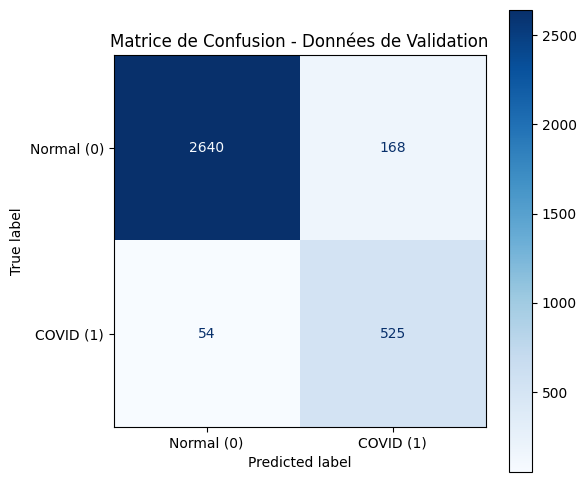

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Prédictions sur le jeu de validation
print("Calcul des prédictions sur les données de validation...")
val_generator.reset()
y_val_pred_prob = model.predict(val_generator)
y_val_pred = (y_val_pred_prob > 0.5).astype(int).flatten()
y_val_true = val_generator.classes

# 2. Génération de la matrice de confusion
cm_val = confusion_matrix(y_val_true, y_val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=["Normal (0)", "COVID (1)"])

# 3. Affichage de la matrice
fig, ax = plt.subplots(figsize=(6, 6))
disp_val.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title('Matrice de Confusion - Données de Validation')
plt.show()

In [14]:
from sklearn.metrics import classification_report

# Génération du rapport de classification détaillé
print("Rapport de classification (Validation) :\n")
print(classification_report(y_val_true, y_val_pred, target_names=["Normal (0)", "COVID (1)"]))

Rapport de classification (Validation) :

              precision    recall  f1-score   support

  Normal (0)       0.98      0.94      0.96      2808
   COVID (1)       0.76      0.91      0.83       579

    accuracy                           0.93      3387
   macro avg       0.87      0.92      0.89      3387
weighted avg       0.94      0.93      0.94      3387



In [15]:
import pandas as pd
from sklearn.metrics import classification_report

# 1. Calcul du rapport sous forme de dictionnaire
report_dict = classification_report(y_val_true, y_val_pred, target_names=["Normal (0)", "COVID (1)"], output_dict=True)

# 2. Conversion en DataFrame
df_report = pd.DataFrame(report_dict).transpose()

# 3. Sauvegarde au format CSV
csv_filename = "classification_repport.csv"
df_report.to_csv(csv_filename, index=True)

# 4. Affichage pour confirmation
print(f"Le rapport de classification a été sauvegardé avec succès sous '{csv_filename}'.")
display(df_report)

Le rapport de classification a été sauvegardé avec succès sous 'classification_repport.csv'.


,precision,recall,f1-score,support
Normal (0),0.979955,0.940171,0.959651,2808.000000
COVID (1),0.757576,0.906736,0.825472,579.000000
accuracy,0.934455,0.934455,0.934455,0.934455
macro avg,0.868766,0.923453,0.892561,3387.000000
weighted avg,0.941940,0.934455,0.936713,3387.000000
